# manasight 05: CLIP linear probe

**Hypothesis H4:** training beats zero-shot. A model that understands content, once it is shown the labels,
clears the palette baseline by a wide margin.

Notebook 04 used CLIP without any training and landed just above the color histogram (36.2% vs 34.0%).
Here CLIP stays exactly as it is, **frozen**. We only train a small classifier on top of the 512 numbers it gives
for every picture. This is called a **linear probe**: it measures how much of the answer is already in the features.

```
picture  ->  CLIP (frozen, about 88 million weights)  ->  512 numbers  ->  our classifier (trained)  ->  color
```

The classifier is the same one as in notebook 03 (logistic regression). Only its input changes:
64 color-box shares there, 512 CLIP numbers here. So the two results can be compared directly:
same model, same split, palette features against content features.

Sections:
1. Load data and the saved CLIP features
2. Train the probe
3. Test results for color
4. Which classes and eras improved
5. What the probe learned, read back as words
6. Does the palette add anything on top?
7. Type
8. Summary

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
from manasight.data import COLOR_CLASSES, COLOR_NAMES, TYPE_CLASSES, load_cards
from manasight.clip import load_image_features, load_word_features
from manasight.eda import load_thumbnails
from manasight.features import color_histogram
from manasight.evaluate import score

plt.rcParams["figure.dpi"] = 72

## 1. Load data and the saved CLIP features

The features were computed once in notebook 04 and saved. Nothing here opens a picture or runs CLIP,
so the whole notebook takes about a minute.

In [2]:
all_cards = load_cards()
not_junk = ~all_cards.is_junk.to_numpy()
cards = all_cards[not_junk].reset_index(drop=True)
features = load_image_features(cards)
print("pictures:", len(cards), "  features:", features.shape)

is_train = (cards.split == "train").to_numpy()
is_val = (cards.split == "val").to_numpy()
is_test = (cards.split == "test").to_numpy()
print(f"train {is_train.sum():,}   val {is_val.sum():,}   test {is_test.sum():,}")

pictures: 47203   features: (47203, 512)
train 35,383   val 4,798   test 3,392


## 2. Train the probe

As in notebook 03: standardize the features (using the training set only), then logistic regression.

One setting to choose, **C**: how freely the model may fit the training data. A small C holds the weights back
(more regularization), a large C lets them grow. With 512 features instead of 64 this matters more,
so we try a few values and keep the one with the best **validation** accuracy.

In [3]:
def train_probe(x_train, y_train, x_val, y_val, classes):
    # try a few values of C, keep the model that is best on the validation set
    best_model = None
    best_accuracy = 0
    for C in (0.0001, 0.001, 0.01):
        model = LogisticRegression(C=C, max_iter=200).fit(x_train, y_train)
        train_accuracy = model.score(x_train, y_train)
        result = score(y_val, model.predict_proba(x_val), model.classes_)
        print(f"C = {C:<7}  train accuracy {train_accuracy:.3f}   val accuracy {result['accuracy']:.3f}   val macro-F1 {result['macro-F1']:.3f}")
        if result["accuracy"] > best_accuracy:
            best_accuracy = result["accuracy"]
            best_model = model
    print("keeping C =", best_model.C)
    return best_model

scaler = StandardScaler().fit(features[is_train])
x = scaler.transform(features)

probe = train_probe(x[is_train], cards.color[is_train], x[is_val], cards.color[is_val], COLOR_CLASSES)

C = 0.0001   train accuracy 0.464   val accuracy 0.463   val macro-F1 0.466
C = 0.001    train accuracy 0.486   val accuracy 0.469   val macro-F1 0.471
C = 0.01     train accuracy 0.494   val accuracy 0.467   val macro-F1 0.470
keeping C = 0.001


**Finding:** C barely matters (46.3% to 46.9% on validation). Training accuracy (49%) is close to validation (47%),
so the probe is not memorizing. Like the histogram model in notebook 03, it is limited by what a single layer can
do with its input, only at a much higher level: 47% instead of 32%.

## 3. Test results for color

The 10 held-out sets. All rows use the same test cards.

In [4]:
test_cards = cards[is_test]
probabilities = probe.predict_proba(x[is_test])
probe_result = score(test_cards.color, probabilities, probe.classes_)

results = pd.DataFrame([
    {"model": "chance", "accuracy": 1 / 7},
    {"model": "always Multicolor", "accuracy": 0.202, "macro-F1": 0.048},
    {"model": "color histogram (03)", "accuracy": 0.340, "macro-F1": 0.304, "top-2": 0.542},
    {"model": "small CNN from scratch (reference project)", "accuracy": 0.368, "macro-F1": 0.345, "top-2": 0.570},
    {"model": "CLIP zero-shot, discovered words (04)", "accuracy": 0.362, "macro-F1": 0.335, "top-2": 0.535},
    {"model": "CLIP linear probe", **probe_result},
]).set_index("model")
results.round(3)

,accuracy,macro-F1,top-2
model,,,
chance,0.143,NaN,NaN
always Multicolor,0.202,0.048,NaN
color histogram (03),0.340,0.304,0.542
small CNN from scratch (reference project),0.368,0.345,0.570
"CLIP zero-shot, discovered words (04)",0.362,0.335,0.535
CLIP linear probe,0.446,0.442,0.675


In [5]:
# the same question on the five single colors only (train and test on single-color cards, 5 classes)
five = COLOR_CLASSES[:5]
train_five = is_train & cards.color.isin(five).to_numpy()
test_five = is_test & cards.color.isin(five).to_numpy()

probe_five = LogisticRegression(C=probe.C, max_iter=200).fit(x[train_five], cards.color[train_five])
five_result = score(cards.color[test_five], probe_five.predict_proba(x[test_five]), probe_five.classes_)
print(f"5 colors only, {test_five.sum():,} test cards (chance 0.200)")
print(f"color histogram (04)        0.481")
print(f"CLIP zero-shot, discovered  0.499")
print(f"CLIP linear probe           {five_result['accuracy']:.3f}")

5 colors only, 2,438 test cards (chance 0.200)
color histogram (04)        0.481
CLIP zero-shot, discovered  0.499
CLIP linear probe           0.596


**Finding:**
- **The trained probe reaches 44.6%,** against 34.0% for the palette and 36.2% for CLIP without training.
  Macro-F1 goes from 0.30 to 0.44, and with two guesses it is right two times out of three (67.5%).
- **Same classifier as notebook 03, only the features changed.** The 10.6 points between them are what CLIP's
  features know beyond 64 color boxes.
- It also clears the reference project's CNN trained from scratch (36.8%) by 8 points, with 30 seconds of training
  on top of a frozen model.
- **On the five colors alone the gap is wider: 59.6%** against 48.1% for the histogram. Three in five single-color
  cards are placed correctly out of five options.

**H4 is supported for "training beats zero-shot":** +8 points over the best zero-shot prompts, from the same features.
The frozen features already held the answer; the labels were needed to read it out.

## 4. Which classes and eras improved

The histogram and zero-shot numbers are copied from notebooks 03 and 04.

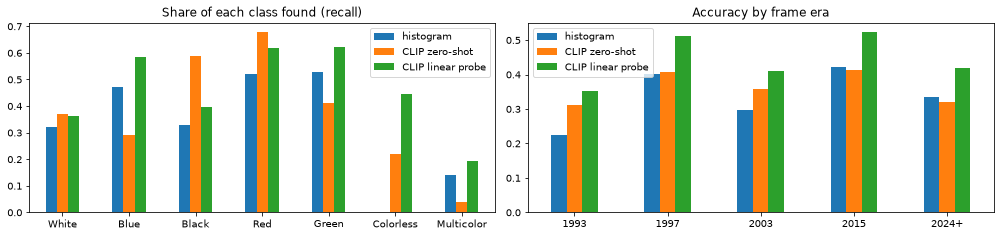

                   White  Blue  Black   Red  Green  Colorless  Multicolor
histogram           0.32  0.47   0.33  0.52   0.53       0.00        0.14
CLIP zero-shot      0.37  0.29   0.59  0.68   0.41       0.22        0.04
CLIP linear probe   0.36  0.58   0.40  0.62   0.62       0.45        0.19

                    1993   1997   2003   2015  2024+
histogram          0.224  0.402  0.298  0.421  0.336
CLIP zero-shot     0.311  0.408  0.358  0.412  0.321
CLIP linear probe  0.352  0.511  0.411  0.524  0.419


In [6]:
predicted = probe.classes_[probabilities.argmax(axis=1)]
matrix = confusion_matrix(test_cards.color, predicted, labels=COLOR_CLASSES, normalize="true")
names = [COLOR_NAMES[c] for c in COLOR_CLASSES]

recall = pd.DataFrame({
    "histogram": [0.32, 0.47, 0.33, 0.52, 0.53, 0.00, 0.14],
    "CLIP zero-shot": [0.37, 0.29, 0.59, 0.68, 0.41, 0.22, 0.04],
    "CLIP linear probe": matrix.diagonal(),
}, index=names)

era_names = ["1993", "1997", "2003", "2015", "2024+"]
probe_by_era = []
for era in era_names:
    in_era = (test_cards.era == era).to_numpy()
    probe_by_era.append(score(test_cards.color[in_era], probabilities[in_era], probe.classes_)["accuracy"])
by_era = pd.DataFrame({
    "histogram": [0.224, 0.402, 0.298, 0.421, 0.336],
    "CLIP zero-shot": [0.311, 0.408, 0.358, 0.412, 0.321],
    "CLIP linear probe": probe_by_era,
}, index=era_names)

fig, axes = plt.subplots(1, 2, figsize=(14, 3.4))
recall.plot.bar(ax=axes[0], rot=0, title="Share of each class found (recall)")
by_era.plot.bar(ax=axes[1], rot=0, title="Accuracy by frame era")
plt.tight_layout()
plt.show()
print(recall.round(2).T.to_string())
print()
print(by_era.round(3).T.to_string())

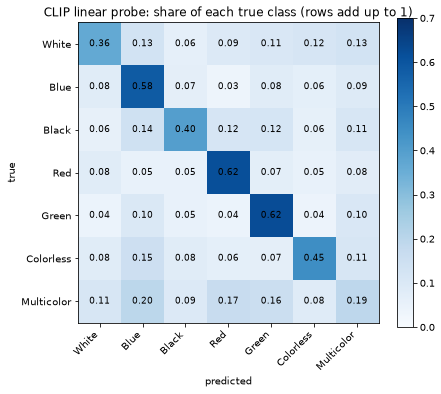

without lands: accuracy 0.452


In [7]:
plt.figure(figsize=(6.5, 5.5))
plt.imshow(matrix, cmap="Blues", vmin=0, vmax=0.7)
plt.xticks(range(7), names, rotation=45, ha="right")
plt.yticks(range(7), names)
for row in range(7):
    for column in range(7):
        plt.text(column, row, f"{matrix[row, column]:.2f}", ha="center", va="center", fontsize=9)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("CLIP linear probe: share of each true class (rows add up to 1)")
plt.colorbar()
plt.tight_layout()
plt.show()

not_land = ~test_cards.is_land.to_numpy()
print(f"without lands: accuracy {score(test_cards.color[not_land], probabilities[not_land], probe.classes_)['accuracy']:.3f}")

**Finding:**
- **The probe beats the palette in every class and every era.** Biggest gains: Colorless 0% to 45%, Blue 47% to 58%,
  Red 52% to 62%, Green 53% to 62%.
- **White (36%) and Black (40%) improve least.** Both are spread over many subjects; the confusion matrix shows them
  leaking into several other classes.
- **Multicolor is still the weak spot (19%).** It is a rule of the game, not a look. Notebook 08 treats it as
  "several colors at once" instead of a class of its own.
- **Zero-shot was better on Black and Red (59%, 68%)** only because it answered those two far too often;
  its overall score was 8 points lower.
- **By era:** 35% on the 1993-era sets, 41% to 52% on the rest. Old art is still the hardest, but the probe gains
  13 points there over the palette (22%).
- Lands make no real difference (45.2% without them).

## 5. What the probe learned, read back as words

The probe has one weight per CLIP number for every color. Those 512 weights are a direction in CLIP's space:
"the more a picture points this way, the more it looks like Red".

CLIP puts words in the same space. So we can ask which of the 13,098 neutral words from notebook 04 lie closest
to each color's direction. Nobody chose these words. They are what the trained model uses, translated into language.

In [8]:
words, all_word_features = load_word_features()

# undo the standardization, and compare every color with the average of all colors
directions = probe.coef_ / scaler.scale_
directions = directions - directions.mean(axis=0)

learned_words = {}
for color, direction in zip(probe.classes_, directions):
    direction = direction / np.linalg.norm(direction)
    closest = np.argsort(-(all_word_features @ direction))[:20]
    learned_words[color] = [words[i] for i in closest]
for color in COLOR_CLASSES:
    print(f"{COLOR_NAMES[color]:10s} {', '.join(learned_words[color])}")

White      albino, beige, angelic, illustrious, whites, white, sunlight, sunshine, daisy, spotlight, blanc, gold, recruiting, duper, heavens, wedding, flour, chino, light, confirmation
Blue       blue, azure, dory, bluebird, aqua, blues, freeze, aquatic, stitch, frosted, kingfisher, icy, turquoise, mackerel, blueprint, colder, eradicate, clap, chilly, swimming
Black      overhaul, stocking, ravens, undertaker, pollock, cell, amethyst, venom, reap, lain, purple, eggplant, mob, taker, lum, daredevil, patchy, punisher, tangle, aku
Red        lava, eruption, molten, volcano, etna, volcanic, inferno, bosh, fiery, crash, blaze, lina, red, gritty, ruby, blazing, redness, flame, horde, carnage
Green      greenery, green, gardening, greener, forest, forestry, vegetation, grassy, evergreen, forestation, gardener, tree, horticulture, foliage, woodland, garden, lum, spring, jungle, greening
Colorless  machinery, item, sculpture, hardware, object, cutlery, chao, ligament, bracelet, stool, weapon, t

**Finding:** the trained model uses both kinds of cue, and which one depends on the color.
- **Colorless is pure content:** machinery, item, sculpture, hardware, object, weapon, metal, machine, robot.
  The probe learned "this picture shows a thing", which is what an artifact is.
- **Red and Green are content that carries its own palette:** lava, eruption, volcano, inferno; greenery, forest,
  vegetation, foliage, jungle. The words "red" and "green" appear too.
- **Blue and White lean on the palette:** blue, azure, aqua, turquoise, icy; white, beige, whites, sunlight, light.
  Content shows up next to it (aquatic, swimming, kingfisher; angelic, heavens, wedding).
- **Black is a mix and the noisiest list:** undertaker, ravens, venom, reap next to purple and amethyst.
- **Multicolor has no theme at all:** different, varied, difference. The model has nothing concrete to hold on to,
  which fits its 19%.

So the answer to "palette or content?" is not the same for every color. This list is a hint, not a measurement:
notebook 06 tests it directly by taking the color out of the pictures.

## 6. Does the palette add anything on top?

If CLIP's features describe content only, adding the color histogram from notebook 03 should help: two different
cues. If adding it changes nothing, CLIP's features already contain the palette.

In [9]:
thumbs, sizes = load_thumbnails(all_cards)
histogram = color_histogram(thumbs[not_junk], bins=4)
histogram = StandardScaler().fit(histogram[is_train]).transform(histogram)

both = np.hstack([x, histogram])
print("features together:", both.shape)
probe_both = train_probe(both[is_train], cards.color[is_train], both[is_val], cards.color[is_val], COLOR_CLASSES)
both_result = score(test_cards.color, probe_both.predict_proba(both[is_test]), probe_both.classes_)

print()
print(f"test accuracy   CLIP only {probe_result['accuracy']:.3f}   CLIP + histogram {both_result['accuracy']:.3f}")
print(f"test macro-F1   CLIP only {probe_result['macro-F1']:.3f}   CLIP + histogram {both_result['macro-F1']:.3f}")

features together: (47203, 576)
C = 0.0001   train accuracy 0.466   val accuracy 0.462   val macro-F1 0.465
C = 0.001    train accuracy 0.490   val accuracy 0.469   val macro-F1 0.471
C = 0.01     train accuracy 0.499   val accuracy 0.463   val macro-F1 0.466
keeping C = 0.001

test accuracy   CLIP only 0.446   CLIP + histogram 0.453
test macro-F1   CLIP only 0.442   CLIP + histogram 0.449


**Finding:** adding the histogram changes almost nothing: 45.3% against 44.6% on test, and no change at all on
validation (46.9% both). **CLIP's features already contain the palette.**

This matters for reading the result above. The probe's 44.6% is not "content only": CLIP sees the colors of a
picture as well as its subjects. What we can say so far is that CLIP's features hold everything the histogram
knows, plus about 10 points more. How much of the total is palette and how much is content is the question for
notebook 06.

## 7. Type

The same probe, trained on the 7 types.

In [10]:
type_probe = train_probe(x[is_train], cards.type[is_train], x[is_val], cards.type[is_val], TYPE_CLASSES)
type_probabilities = type_probe.predict_proba(x[is_test])
type_result = score(test_cards.type, type_probabilities, type_probe.classes_)

type_results = pd.DataFrame([
    {"model": "always Creature", "accuracy": 0.499, "macro-F1": 0.095},
    {"model": "color histogram (03)", "accuracy": 0.498, "macro-F1": 0.095, "top-2": 0.608},
    {"model": "small CNN from scratch (reference project)", "accuracy": 0.529, "macro-F1": 0.286},
    {"model": "CLIP zero-shot, discovered words (04)", "accuracy": 0.373, "macro-F1": 0.284, "top-2": 0.581},
    {"model": "CLIP linear probe", **type_result},
]).set_index("model")
type_results.round(3)

C = 0.0001   train accuracy 0.615   val accuracy 0.587   val macro-F1 0.308
C = 0.001    train accuracy 0.638   val accuracy 0.603   val macro-F1 0.383
C = 0.01     train accuracy 0.648   val accuracy 0.605   val macro-F1 0.428
keeping C = 0.01


,accuracy,macro-F1,top-2
model,,,
always Creature,0.499,0.095,NaN
color histogram (03),0.498,0.095,0.608
small CNN from scratch (reference project),0.529,0.286,NaN
"CLIP zero-shot, discovered words (04)",0.373,0.284,0.581
CLIP linear probe,0.578,0.396,0.742


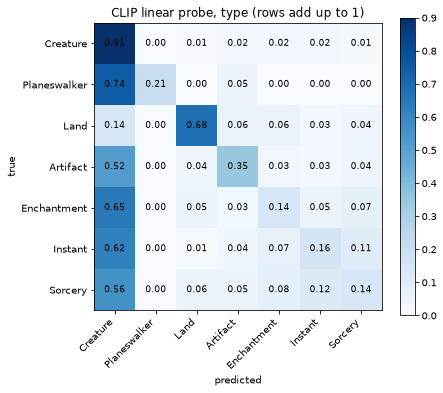

                   Creature  Planeswalker  Land  Artifact  Enchantment  Instant  Sorcery
CLIP zero-shot         0.47          0.47  0.50      0.37         0.06     0.49     0.04
CLIP linear probe      0.91          0.21  0.68      0.35         0.14     0.16     0.14


In [11]:
type_predicted = type_probe.classes_[type_probabilities.argmax(axis=1)]
type_matrix = confusion_matrix(test_cards.type, type_predicted, labels=TYPE_CLASSES, normalize="true")

plt.figure(figsize=(6.5, 5.5))
plt.imshow(type_matrix, cmap="Blues", vmin=0, vmax=0.9)
plt.xticks(range(7), TYPE_CLASSES, rotation=45, ha="right")
plt.yticks(range(7), TYPE_CLASSES)
for row in range(7):
    for column in range(7):
        plt.text(column, row, f"{type_matrix[row, column]:.2f}", ha="center", va="center", fontsize=9)
plt.xlabel("predicted")
plt.ylabel("true")
plt.title("CLIP linear probe, type (rows add up to 1)")
plt.colorbar()
plt.tight_layout()
plt.show()

type_recall = pd.DataFrame({"CLIP zero-shot": [0.47, 0.47, 0.50, 0.37, 0.06, 0.49, 0.04],
                            "CLIP linear probe": type_matrix.diagonal()}, index=TYPE_CLASSES)
print(type_recall.round(2).T.to_string())

**Finding:**
- **Type from art: 57.8% accuracy, 0.396 macro-F1,** against 49.9% and 0.095 for "always Creature", and 52.9% and
  0.286 for the reference project's trained CNN. The right type is in the top two guesses 74% of the time.
- **Creatures (91%) and lands (68%) are easy:** a figure, or a place.
- **Artifacts are found a third of the time (35%).**
- **Planeswalker, Enchantment, Instant and Sorcery stay hard (14% to 21%).** The confusion matrix shows most of
  them answered as Creature: a spell is usually painted as someone casting it.
- Zero-shot found more instants (49%) but only by guessing Instant too often; its accuracy was 37%.
- C = 0.01 was the best and also the largest value tried, so the type probe may have a little more to give.

The palette had nothing to say about type. All of this comes from content.

## 8. Summary

| Test set, color (7 classes) | Accuracy | Macro-F1 | Top-2 | 5 colors only |
|---|---|---|---|---|
| Always Multicolor | 20.2% | 0.048 | | |
| Color histogram (03) | 34.0% | 0.304 | 54.2% | 48.1% |
| CLIP zero-shot, discovered words (04) | 36.2% | 0.335 | 53.5% | 49.9% |
| **CLIP linear probe** | **44.6%** | **0.442** | **67.5%** | **59.6%** |
| CLIP + histogram, linear probe | 45.3% | 0.449 | | |

| Test set, type (7 classes) | Accuracy | Macro-F1 | Top-2 |
|---|---|---|---|
| Always Creature | 49.9% | 0.095 | |
| CLIP zero-shot, discovered words (04) | 37.3% | 0.284 | 58.1% |
| **CLIP linear probe** | **57.8%** | **0.396** | **74.2%** |

- **H4 supported:** with labels, the same frozen CLIP features go from 36.2% to 44.6% on color, 10.6 points above
  the palette model, using the identical classifier.
- The probe is better than the palette in every class and every era. Colorless goes from invisible to 45%.
- Read back as words, the probe uses content for Colorless, content with its own palette for Red and Green,
  and mostly palette for Blue and White.
- CLIP's features already include the palette (adding the histogram gives nothing), so this result alone does not
  say how much is content.
- Training and validation accuracy are close (49% and 47%): the single layer is the limit, not the amount of data.

**Next:** a small neural network on the same features (can a bigger classifier get more out of them?),
then fine-tuning CLIP itself on a GPU.